In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import fmatoolbox as fma
import isautilities as isau
import xarray as xr
import itertools
import scipy as sp
import warnings

regs = ('hpc','nr','pfc')
import pathlib
froot = pathlib.Path().cwd().parent.parent.parent / 'Results'
fig_root = froot / 'Figures' / 'ISAHpcPfc' / 'XCorr'
fig_root_supp = froot / 'Figures' / 'ISAHpcPfc' / 'Supp'
fig_root_poster = froot / 'PosterFigures'
fres = froot / 'Data' / 'unitPECorr.pkl'
batch_file = '/mnt/hubel-data-103/Pietro/InfraSlowNRPaper/Data/IS_intervals.batch'
results = {}
do_save = False

In [2]:
def _laggedSpikeCrossCorr(session, when='sleep.*#0', regs=None, event='deltaWaves', bin=0.1, n_bins=5, step=5, target=0, shift=50, shuffle=1, pairs=None):
    # compute lagged cross-region pairwise unit correlation around event times as (shuffle, region, lag) XArray
    # interpretation: in 'reg1-reg2', reg1 target (controlled by 'target'), reg2 source (all are always computed)
    # time resolution will be 'bin' / 'step'
    # 'shuffle' coordinate is False iff corresponding data values are real

    R = fma.regions.regions(session, epochs=when, states='sws', events='InfraSlowRhythm/infraslowaval')
    regs = R.ids if regs is None else np.array(regs)
    if event in ['ripples','deltaWaves','spindles','down']:
        event_t, is_isa = isau.loadHpcPfcEvents(session,names=event,regions=R,isa=R.eventIntervals('slownr'),sleep=R.eventIntervals('sws'))
        event_t = event_t[event]
        is_isa = is_isa[event]
    else:
        event_t = isau.ISTransitions(isa=R.eventIntervals('slownr'),on=R.eventIntervals('slowavalnr'))[int(event=='on_off')] # CHECK
    if len(event_t) == 0:
        return None

    def spear(a, b):
        # spearman correlation of pairs of columns of a and b
        ra = sp.stats.rankdata(a, axis=0); rb = sp.stats.rankdata(b, axis=0) # rank
        ra = (ra - ra.mean(0)) / ra.std(0); rb = (rb - rb.mean(0)) / rb.std(0) # standardize
        return ra.T @ rb / a.shape[0] # (n, m)

    # region pairs
    if pairs is None:
        reg_pair_idx = [list(p) for p in itertools.product(range(len(regs)), repeat=2)] # make pairs preserving order
    else:
        reg_pair_idx = pairs
    reg_pairs = [f'{regs[rp[0]]}-{regs[rp[1]]}' for rp in reg_pair_idx]
    is_reg = np.isin(regs, R.ids) # is_reg[i] is True if regs[i] is in R.ids
    unit_range = {regs[i]: R.units(regs[i])[[0,-1]] if r else None for i, r in enumerate(is_reg)}
    _, unit_reg = R.units(regs=regs[is_reg], return_reg=True)

    # 1. count spikes in overlapping windows around event times
    limits = (-n_bins*bin/2, n_bins*bin/2)
    n_times = (n_bins-1) * step + 1
    peths = {}
    for j, r in enumerate(regs[is_reg]):
        s = R.spikes(r)
        peths[r], times, _ = fma.analysis.PETH(s[:,0], event_t, limits=limits, n_bins=n_bins, step=step, groups=s[:,1], g_range=unit_range[r], fast=True) # (event, lag, unit)
        if n_times != len(times):
            print('!')

    # define target times, if target is None: special case, results are one the transposed of the other
    skip = target is None
    target = np.arange(n_times) if skip else n_times//2 + np.array(target,ndmin=1) # center + offset given by 'target' input

    rng = np.random.default_rng()
    n_pairs = len(reg_pairs)

    n_units = len(unit_reg)
    spearman2 = np.full((2,shuffle+1,n_units,n_units,n_times,len(target)), np.nan) # (isa, shuffle, unit, unit, source lag, target lag)
    spearman3 = np.full((2,shuffle+1,n_units,n_units,n_times,len(target)), np.nan) # (isa, shuffle, unit, unit, source lag, target lag)
    # 0: ISA, 1: nISA
    for isa in range(2):
        valid = is_isa == isa

        ref_peth = np.concatenate([p[valid] for p in peths.values()], axis=2)
        # 0: observed, next: surrogate (roll across events)
        for k in range(shuffle+1):
            lagged_peth = np.roll(ref_peth.copy(), shift=rng.integers(-shift,shift+1), axis=0) if k else ref_peth.copy()
            n_keep_units = lagged_peth.shape[2] # used to recover the ref-to-lagged block in spearmanr output

            # source * target lags
            for sour in range(n_times):
                for tar, t_target in enumerate(target):
                    with np.errstate(invalid='ignore'): # suppress 0 / 0 warning
                        with warnings.catch_warnings():
                            warnings.filterwarnings('ignore', category=sp.stats.ConstantInputWarning)
                            spr = sp.stats.spearmanr(ref_peth[:,t_target,:], lagged_peth[:,sour,:]).statistic
                            if isinstance(spr, float): spr = np.full((n_keep_units*2,n_keep_units*2), spr)
                            spearman2[isa,k,:,:,sour,tar] = spr[:n_keep_units,n_keep_units:]
                            spearman3[isa,k,:,:,sour,tar] = spear(ref_peth[:,t_target,:], lagged_peth[:,sour,:])
    print(np.mean(np.isclose(spearman2, spearman3, equal_nan=True)))
    spearman2 = xr.DataArray(spearman2, dims=('isa','shuffle','reg0','reg1','lag','target'), coords={'isa':[True,False], 'shuffle':[False]+[True]*shuffle,
                            'reg0':unit_reg, 'reg1':unit_reg, 'lag':times, 'target':times[target], 'event':event, 'rat':int(R.rat), 'base':R.basename})
    mean_spear = np.abs(spearman2).stack(multi=('reg0','reg1'))
    key = mean_spear.reg0.astype(str) + "-" + mean_spear.reg1.astype(str) # 1d along reg
    mean_spear = mean_spear.assign_coords(reg=key).groupby("reg").mean("multi", skipna=True)

    spearman = np.full((2,shuffle+1,n_pairs,n_times,len(target)), np.nan) # (isa, shuffle, reg, source lag, target lag)
    skip = False
    # 0: ISA, 1: nISA
    for isa in range(2):
        valid = is_isa == isa

        # region pairs
        for i, rp in enumerate(reg_pair_idx):
            if rp[0] <= rp[1] or not skip:
                if is_reg[rp[0]] and is_reg[rp[1]]:
                    ref_peth = peths[regs[rp[0]]][valid]

                    # 0: observed, next: surrogate (roll across events)
                    for k in range(shuffle+1):
                        lagged_peth = np.roll(peths[regs[rp[1]]][valid], shift=rng.integers(-shift,shift+1), axis=0) if k else peths[regs[rp[1]]][valid]
                        n_keep_units = lagged_peth.shape[2] # used to recover the cross-correlation block in spearmanr output

                        # source * target lags
                        for sour in range(n_times):
                            for tar, t_target in enumerate(target):
                                with np.errstate(invalid='ignore'): # suppress 0 / 0 warning
                                    with warnings.catch_warnings():
                                        warnings.filterwarnings('ignore', category=sp.stats.ConstantInputWarning)
                                        spr = sp.stats.spearmanr(lagged_peth[:,sour,:], ref_peth[:,t_target,:])[0]
                                spearman[isa,k,i,sour,tar] = np.nanmean(np.abs(spr[:n_keep_units,n_keep_units:]))
            if skip:
                j = rp[1] * len(regs) + rp[0]
                spearman[:,:,j] = spearman[:,:,i].swapaxes(-1,-2)

    spearman = xr.DataArray(spearman, dims=('isa','shuffle','reg','lag','target'),
                            coords={'isa': [True,False], 'shuffle': [False]+[True]*shuffle, 'reg': reg_pairs, 'lag': times, 'target': times[target], 'event': event, 'rat': int(R.rat)})

    AA = mean_spear.transpose(*spearman.dims)
    print(np.mean(np.isclose(AA.sel(shuffle=False), spearman.sel(shuffle=False), equal_nan=True)))

    return spearman2, mean_spear

In [ ]:
# test one session
# NOTE: bin 0.05 for curves, 0.1 ok for color maps
session = fma.data.readBatchFile(batch_file)[0][11]
print(f'session: {session}')
xdata, xdatam = _laggedSpikeCrossCorr(session, event='ripples', target=None, shuffle=2, n_bins=3, step=2)

session: /mnt/hubel-data-139/perceval/Rat003_20231227/Rat003_20231227.xml


In [ ]:
# interpretation: reg1 pop vector at transition correlated with reg2's delayed
fig, axs = fma.plotting.figure(f'Lagged pairwise correlation around {xdata.event.values}',n=(1,9),size=(35,8))
for i, r in enumerate(xdata.reg.values):
    reg_data = xdata.sel(reg=r, target=0, isa=True)
    fma.plotting.semPlot(xdata.lag, reg_data.sel(shuffle=True), color=isau.paperColors('shuffle'), label=str(r.item().upper()),ax=axs[i])
    axs[i].plot(xdata.lag, reg_data.sel(shuffle=False), color=isau.paperColors(i), label=str(r.item().upper()))
    axs[i].set_xlabel(f't from {xdata.event.values} (s)'), axs[i].set_title(r)
    axs[i].axvline(0, ls='--', color='k')
axs[0].set_ylabel('corr');

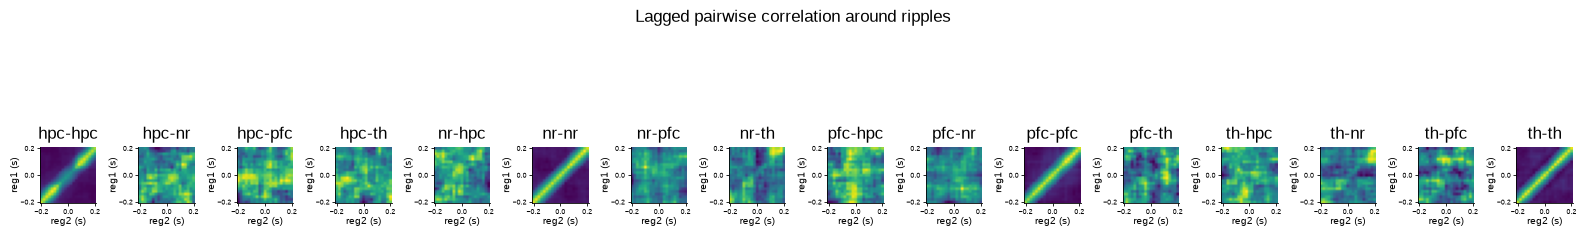

In [4]:
# interpretation: reg1 target, reg2 source
fig, ax = fma.plotting.figure(f'Lagged pairwise correlation around {xdata.event.values}',n=(1,16),size=(40,8))
for i, r in enumerate(xdata.reg.values):
    reg_data = xdata.sel(reg=r, isa=True)
    fma.plotting.plotColorMap(reg_data.sel(shuffle=False).T, x=reg_data.lag, y=reg_data.target, ax=ax[i])
    ax[i].set(title=r,xlabel='reg2 (s)',ylabel='reg1 (s)')

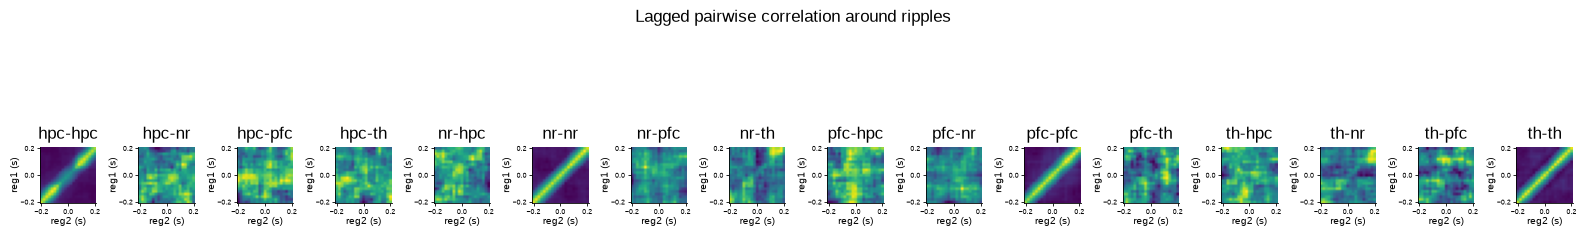

In [5]:
# interpretation: reg1 target, reg2 source
fig, ax = fma.plotting.figure(f'Lagged pairwise correlation around {xdata.event.values}',n=(1,16),size=(40,8))
k = 0
for i, r0 in enumerate(np.unique(xdata2.reg0.values)):
    for j, r1 in enumerate(np.unique(xdata2.reg1.values)):
        reg_data = xdata2.sel(reg0=r0, reg1=r1, isa=True, shuffle=False)
        reg_data = np.nanmean(np.abs(reg_data), axis=(0,1))
        fma.plotting.plotColorMap(reg_data.T, x=xdata2.lag, y=xdata2.target, ax=ax[k])
        ax[k].set(title=f'{r0}-{r1}', xlabel='reg2 (s)', ylabel='reg1 (s)')
        k += 1

In [ ]:
# test one session
session = fma.data.readBatchFile(batch_file)[0][30]
print(f'session: {session}')
xdata = _laggedSpikeCrossCorr(session,event='off_on',bin=0.1,n_bins=31,step=1,target=None,shift=5)

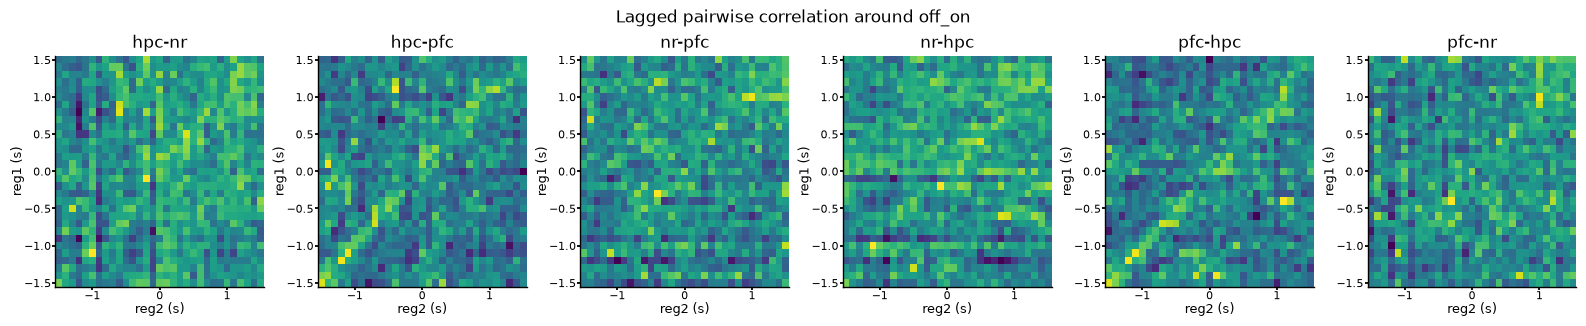

In [7]:
# see OFF-ON
fig, ax = fma.plotting.figure(f'Lagged pairwise correlation around {xdata.event.values}',n=(1,6),size=(40,8))
for i, r in enumerate(xdata.reg.values):
    reg_data = xdata.sel(reg=r)
    fma.plotting.plotColorMap(reg_data.sel(shuffle=False).T,x=reg_data.lag,y=reg_data.target,ax=ax[i])
    ax[i].set(title=r,xlabel='reg2 (s)',ylabel='reg1 (s)')

batch for delta waves (tried wider limits, no difference)

In [5]:
corr_delta = fma.data.runBatch(batch_file, _laggedSpikeCrossCorr, regs=regs, event='down', target=None, shuffle=100, drop_fail=True, parallel=True)
corr_delta_cat = xr.concat(corr_delta, dim='rat', join='outer')
results['delta'] = corr_delta_cat
isau.update_results(results, fres)


Starting Batch, 2026-11-18 02:27:14.912313 

Error in session /mnt/hubel-data-139/karadoc/Rat004_20240303/Rat004_20240303.xml (17)
'float' object is not subscriptable
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.xml (31)
/mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.xml (32)
/mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.xml (33)
/mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230819/Rat002_20230819.xml (38)
'float' object is not subscriptable
Traceback:
Error in session /mnt/hubel-data-129/blinky/Rat002_20230821/Rat002_20230821.xml (40)
'float' object is not subscript

In [3]:
corr_delta = fma.data.runBatch(batch_file, _laggedSpikeCrossCorr, when='sleep.*#1', regs=regs, event='down', target=None, shuffle=100, drop_fail=True, parallel=True)
corr_delta_cat = xr.concat(corr_delta, dim='rat', join='outer')
results['delta_s2'] = corr_delta_cat
isau.update_results(results, fres)


Starting Batch, 2026-11-18 18:34:05.354923 



/tmp/ipykernel_4034289/2413929542.py:66: RuntimeWarning: Mean of empty slice
/tmp/ipykernel_4034289/2413929542.py:66: RuntimeWarning: Mean of empty slice
/tmp/ipykernel_4034289/2413929542.py:66: RuntimeWarning: Mean of empty slice
/tmp/ipykernel_4034289/2413929542.py:66: RuntimeWarning: Mean of empty slice
/tmp/ipykernel_4034289/2413929542.py:66: RuntimeWarning: Mean of empty slice
/tmp/ipykernel_4034289/2413929542.py:66: RuntimeWarning: Mean of empty slice
/tmp/ipykernel_4034289/2413929542.py:66: RuntimeWarning: Mean of empty slice
/tmp/ipykernel_4034289/2413929542.py:66: RuntimeWarning: Mean of empty slice
/tmp/ipykernel_4034289/2413929542.py:66: RuntimeWarning: Mean of empty slice
/tmp/ipykernel_4034289/2413929542.py:66: RuntimeWarning: Mean of empty slice
/tmp/ipykernel_4034289/2413929542.py:66: RuntimeWarning: Mean of empty slice
/tmp/ipykernel_4034289/2413929542.py:66: RuntimeWarning: Mean of empty slice
/tmp/ipykernel_4034289/2413929542.py:66: RuntimeWarning: Mean of empty slice

Error in session /mnt/hubel-data-139/karadoc/Rat004_20240303/Rat004_20240303.xml (17)
'float' object is not subscriptable
Traceback:
Error in session /mnt/hubel-data-140/karadoc/Rat004_20240313/Rat004_20240313.xml (24)
'float' object is not subscriptable
Traceback:
Error in session /mnt/hubel-data-140/karadoc/Rat004_20240318/Rat004_20240318.xml (29)
'float' object is not subscriptable
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.xml (31)
/mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.xml (32)
/mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.xml (33)
/mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/

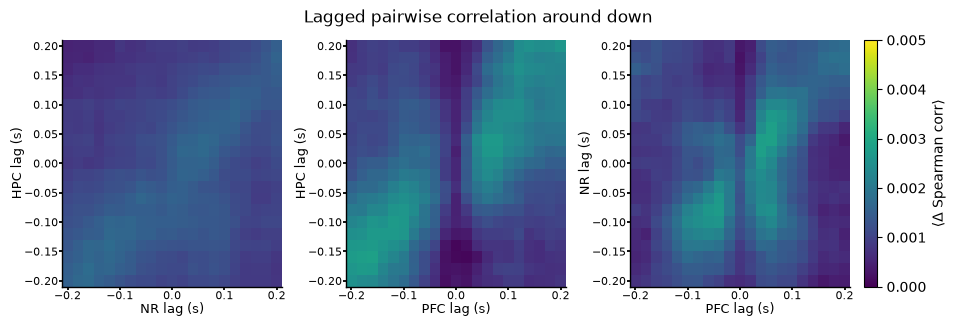

In [121]:
# interpretation: reg1 target, reg2 source
# DRAW 3D SURPHACES + PLANE THAT SLICES + one plot with 3 curves showing temporality of 3 peaks
fig, ax = fma.plotting.figure(f'Lagged pairwise correlation around {corr_delta_cat.event.values}',n=(1,3),size=(24,8))
vmin = 0. # 0.026 # for absolute values (not difference)
vmax = 0.005 # 0.032 # for absolute values (not difference)
label = [None,None,r'$\langle$﷿﷿ Spearman corr$\rangle$']
for i, r in enumerate(corr_delta_cat.reg.values[:3]):
    reg_data = corr_delta_cat.sel(reg=r,isa=True)
    reg_data = reg_data.sel(shuffle=False) - reg_data.sel(shuffle=True)

    # plot result
    isau.plotCMap(reg_data.mean(dim='rat',skipna=True).T,vmin=vmin,vmax=vmax,bar=label[i],ax=ax[i],reg=r)

    # significance
    w = sp.stats.wilcoxon(reg_data,axis=0,nan_policy='omit',alternative='greater').pvalue
    _, h = fma.analysis.holmBonferroni(w,return_reject=True)

PFC lag: 0.06 s


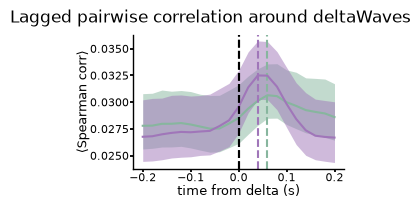

In [26]:
# plot slice of PFC at 50 ms after delta
fig, ax = fma.plotting.figure(f'Lagged pairwise correlation around {corr_delta_cat.event.values}',size=(7,5))
for i, r in enumerate(corr_delta_cat.reg.values[1:3]):
    reg_data = corr_delta_cat.sel(reg=r).sel(target=0.05,method='nearest')
    reg_data = reg_data.sel(shuffle=False)# - reg_data.sel(shuffle=True)

    # plot result
    fma.plotting.semPlot(reg_data.lag,reg_data,ax=ax[0],color=isau.paperColors(r.split('-')[0]))

    # significance
    peak_time = np.argmax(reg_data.mean('rat').data)
    ax[0].axvline(reg_data.lag[peak_time],ls='--',color=isau.paperColors(r.split('-')[0])),
    ax[0].axvline(0,ls='--',color='k')
print(f'PFC lag: {reg_data.target.values} s')
ax[0].set(xlabel='time from delta (s)',ylabel=r'$\langle$Spearman corr$\rangle$');

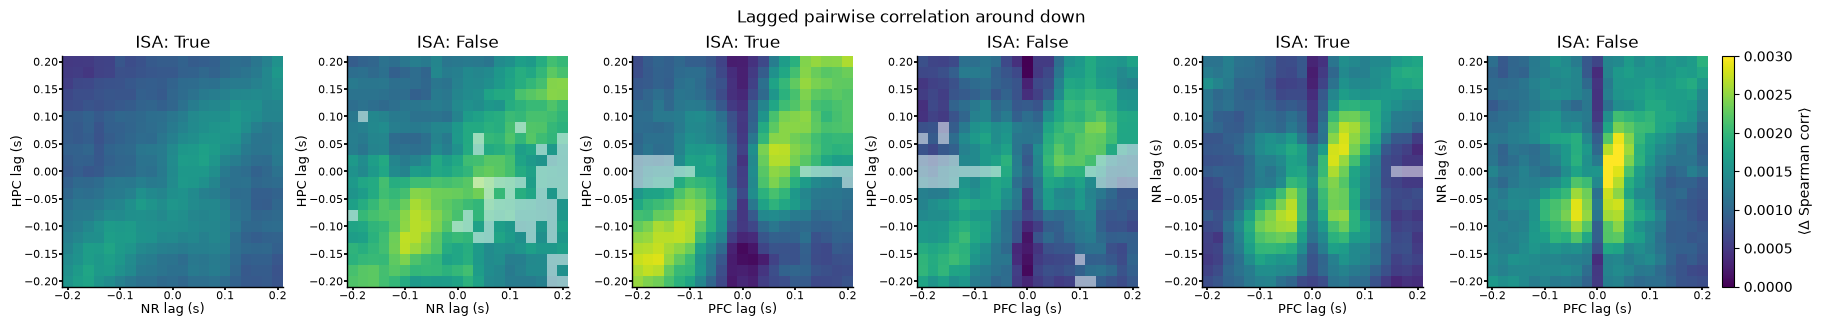

In [17]:
# divide ISA / nISA
# interpretation: reg1 target, reg2 source
# SHOW THAT LOWER TRIANGULAR PARTS ARE OF OPPOSITE MEANING! in hpc-nr and nr-pfc
# DRAW 3D SURPHACES + PLANE THAT SLICES + one plot with 3 curves showing temporality of 3 peaks
fig, ax = fma.plotting.figure(f'Lagged pairwise correlation around {corr_delta_cat.event.values}',n=(1,6),size=(46,8))
vmin = 0.
vmax = 0.003
label = [None,None,None,None,None,r'$\langle$﷿﷿ Spearman corr$\rangle$']
for i, r in enumerate(corr_delta_cat.reg.values[:3]):
    for a, isa in enumerate([True,False]):
        reg_data = corr_delta_cat.sel(reg=r,isa=isa)
        reg_data = reg_data.sel(shuffle=False) - reg_data.sel(shuffle=True)
        # significance
        w = sp.stats.wilcoxon(reg_data,axis=0,nan_policy='omit',alternative='greater').pvalue
        _, h = fma.analysis.holmBonferroni(w,return_reject=True)
        # plot result
        out = plotCMap(reg_data.mean(dim='rat',skipna=True).T,vmin=vmin,vmax=vmax,smooth=.2,alpha=np.where(h,1.0,0.5),bar=label[2*i+a],ax=ax[2*i+a],reg=r)
        label[2*i+a] is not None and out[1].ax.ticklabel_format(axis='y', style='sci', scilimits=(-2,-2))
        ax[2*i+a].set(title=f'ISA: {isa}')
do_save and fma.plotting.saveFigure(fig,fig_root / 'deltaXCorr2',('png','svg'))

hpc ISA True 0.06 s, hpc ISA False 0.12 s, nr ISA True 0.06 s, nr ISA False 0.04 s, 

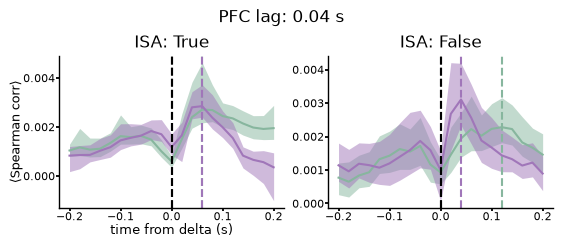

In [145]:
# plot slice of PFC at 50 ms after delta
fig, ax = fma.plotting.figure(n=(1,2),size=(14,6))
for i, r in enumerate(corr_delta_cat.reg.values[1:3]):
    for a, isa in enumerate([True,False]):
        reg_data = corr_delta_cat.sel(reg=r,isa=isa).sel(target=0.03,method='nearest')
        reg_data = reg_data.sel(shuffle=False) - reg_data.sel(shuffle=True)

        # plot result
        fma.plotting.semPlot(reg_data.lag,reg_data,ax=ax[a],color=isau.paperColors(r.split('-')[0]))

        # peak time
        peak_time = np.argmax(reg_data.mean('rat').data)
        ax[a].axvline(reg_data.lag[peak_time],ls='--',color=isau.paperColors(r.split('-')[0]))
        print(f'{r.item().split('-')[0]} ISA {isa} {reg_data.lag[peak_time].values:.2f} s, ',end='')
        ax[a].axvline(0,ls='--',color='k')
        ax[a].set(title=f'ISA: {isa}')
fig.suptitle(f'PFC lag: {reg_data.target.values:.2f} s')
ax[0].set(xlabel='time from delta (s)',ylabel=r'$\langle$Spearman corr$\rangle$')
do_save and fma.plotting.saveFigure(fig,fig_root / 'deltaXCorr',('png','svg'))

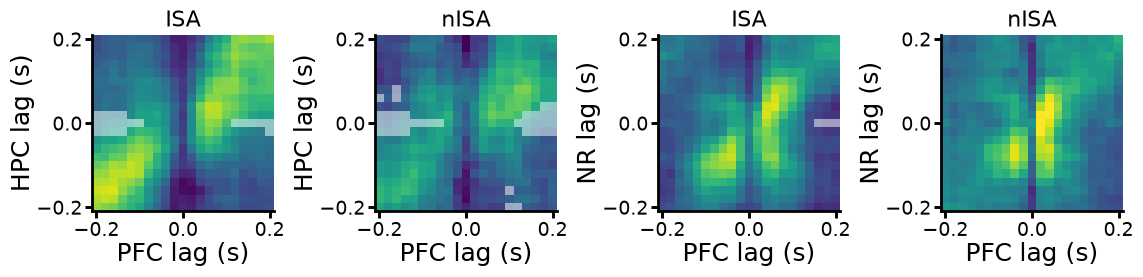

In [26]:
# poster figure
fig, ax = fma.plotting.figure(n=(1,4),size=(11.5,2.7),format='poster')
vmin = 0.
vmax = 0.003
label = [None,None,None,None,None,r'$\langle$﷿﷿ Spearman corr$\rangle$']
for i, r in enumerate(corr_delta_cat.reg.values[1:3]):
    for a, isa in enumerate([True,False]):
        reg_data = corr_delta_cat.sel(reg=r,isa=isa)
        reg_data = reg_data.sel(shuffle=False) - reg_data.sel(shuffle=True)
        # significance
        w = sp.stats.wilcoxon(reg_data,axis=0,nan_policy='omit',alternative='greater').pvalue
        _, h = fma.analysis.holmBonferroni(w,return_reject=True)
        # plot result
        out = plotCMap(reg_data.mean(dim='rat',skipna=True).T,vmin=vmin,vmax=vmax,smooth=.2,alpha=np.where(h,1.0,0.5),bar=label[2*i+a],ax=ax[2*i+a],reg=r)
        label[2*i+a] is not None and out[1].ax.ticklabel_format(axis='y', style='sci', scilimits=(-2,-2))
        ax[2*i+a].set_title('ISA' if isa else 'nISA',fontsize=16)
do_save and fma.plotting.saveFigure(fig,fig_root_poster / 'deltaXCorr2',('png','svg'))

hpc ISA True 0.06 s, hpc ISA False 0.12 s, nr ISA True 0.06 s, nr ISA False 0.04 s, 

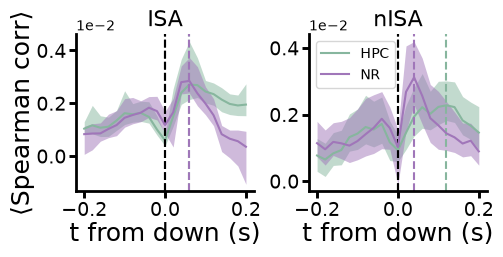

In [36]:
# poster figure
fig, ax = fma.plotting.figure(n=(1,2),size=(5,2.5),format='poster')
for i, r in enumerate(corr_delta_cat.reg.values[1:3]):
    for a, isa in enumerate([True,False]):
        reg_data = corr_delta_cat.sel(reg=r,isa=isa).sel(target=0.03,method='nearest')
        reg_data = reg_data.sel(shuffle=False) - reg_data.sel(shuffle=True)

        # plot result
        ax[a].axvline(0,ls='--',color='k')
        fma.plotting.semPlot(reg_data.lag,reg_data,ax=ax[a],color=isau.paperColors(r.split('-')[0]),label=r.split('-')[0].upper())

        # peak time
        peak_time = np.argmax(reg_data.mean('rat').data)
        ax[a].axvline(reg_data.lag[peak_time],ls='--',color=isau.paperColors(r.split('-')[0]))
        print(f'{r.item().split('-')[0]} ISA {isa} {reg_data.lag[peak_time].values:.2f} s, ',end='')

        ax[a].set(xlabel='t from down (s)')
        ax[a].ticklabel_format(axis='y', style='sci', scilimits=(-2,-2))
        ax[a].set_title('ISA' if isa else 'nISA',fontsize=16)
ax[0].set(ylabel=r'$\langle$Spearman corr$\rangle$'); ax[1].legend()
do_save and fma.plotting.saveFigure(fig,fig_root_poster / 'deltaXCorr',('png','svg'))

batch for ripples

In [3]:
corr_rip, mean_rip = fma.data.runBatch(batch_file, _laggedSpikeCrossCorr, regs=regs, event='ripples', target=None, shuffle=1, drop_fail=True, parallel=True) # WAS 100
#corr_rip_cat = xr.concat(corr_rip, dim='rat', join='outer')
#results['rip'] = corr_rip_cat
#isau.update_results(results, fres)


Starting Batch, 2026-11-23 18:25:53.427332 

Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.xml (31)
/mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.xml (32)
/mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.xml (33)
/mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.sws not found.
Traceback:
Error in session /mnt/hubel-data-129/blinky/Rat002_20230822/Rat002_20230822.xml (41)
/mnt/hubel-data-129/blinky/Rat002_20230822/Rat002_20230822.sws not found.
Traceback:
Error in session /mnt/hubel-data-129/blinky/Rat002_20230823/Rat002_20230823.xml (42)
/mnt/hubel-data-129/blinky/Rat002_20230823/Rat002_20230823.sws not found.
Traceback:
Batch completed with 5 errors, 2026-11-23 18:31:32

In [4]:
corr_rip = fma.data.runBatch(batch_file, _laggedSpikeCrossCorr, when='sleep.*#1', regs=regs, event='ripples', target=None, shuffle=100, drop_fail=True, parallel=True)
corr_rip_cat = xr.concat(corr_rip, dim='rat', join='outer')
results['rip_s2'] = corr_rip_cat
isau.update_results(results, fres)


Starting Batch, 2026-11-17 20:48:59.531460 

Error in session /mnt/hubel-data-139/karadoc/Rat004_20240303/Rat004_20240303.xml (17)
'float' object is not subscriptable
Traceback:
Error in session /mnt/hubel-data-140/karadoc/Rat004_20240313/Rat004_20240313.xml (24)
'float' object is not subscriptable
Traceback:
Error in session /mnt/hubel-data-140/karadoc/Rat004_20240318/Rat004_20240318.xml (29)
'float' object is not subscriptable
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.xml (31)
/mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.xml (32)
/mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.xml (33)
/mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.sws not found.
Tr

(45, 21, 21)
(45, 21, 21)


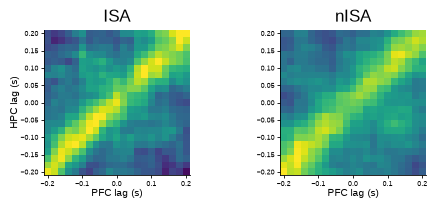

In [10]:
# divide ISA / nISA
def mask_quadrant(x, a=-2, b=-2, c=15, d=15, n=5):
    i, j = np.indices(x.shape[-2:])
    mask = (i <= len(i)//2 + c) & (j <= len(j)//2 + d) & (i >= len(i)//2 + a) & (j >= len(j)//2 + b) & (i - j > -n) & (i - j < n)
    x = np.where(mask,x,np.nan) # upper-right quadrant
    return x
fig, ax = fma.plotting.figure(n=(1,2),size=(12,5))
r = 'hpc-pfc'
vmin = 0.001
vmax = 0.004
label = [None,r'$\langle$﷿﷿ Spearman corr$\rangle$']
for a, isa in enumerate([True,False]):
    reg_data = mean_rip_cat.sel(reg='hpc-pfc', isa=isa)
    reg_data = reg_data.sel(shuffle=False) - reg_data.sel(shuffle=True)#.mean(dim='shuffle')
    # significance
    #w = sp.stats.wilcoxon(reg_data,axis=0,nan_policy='omit',alternative='greater').pvalue
    #_, h = fma.statistics.holmBonferroni(w,return_reject=True)
    # plot result
    print(reg_data.shape)
    reg_data = reg_data.mean(dim='rat',skipna=True).T
    #reg_data.values = mask_quadrant(reg_data.values, a=-5, b=-5, c=10, d=10, n=17)
    isau.plotCMap(reg_data, ax=ax[a], reg=r, vmin=vmin, vmax=vmax)
    ax[a].set(title='ISA' if isa else 'nISA')
ax[1].set(ylabel='');

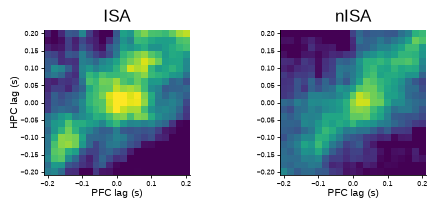

In [9]:
# divide ISA / nISA
def mask_quadrant(x, a=-2, b=-2, c=15, d=15, n=5):
    i, j = np.indices(x.shape[-2:])
    mask = (i <= len(i)//2 + c) & (j <= len(j)//2 + d) & (i >= len(i)//2 + a) & (j >= len(j)//2 + b) & (i - j > -n) & (i - j < n)
    x = np.where(mask,x,np.nan) # upper-right quadrant
    return x
fig, ax = fma.plotting.figure(n=(1,2),size=(12,5))
r = 'hpc-pfc'
vmin = 0.001
vmax = 0.0026
label = [None,r'$\langle$﷿﷿ Spearman corr$\rangle$']
for a, isa in enumerate([True,False]):
    reg_data = corr_rip_cat.sel(reg=r,isa=isa)
    reg_data = reg_data.sel(shuffle=False) - reg_data.sel(shuffle=True).mean(dim='shuffle')
    # significance
    #w = sp.stats.wilcoxon(reg_data,axis=0,nan_policy='omit',alternative='greater').pvalue
    #_, h = fma.statistics.holmBonferroni(w,return_reject=True)
    # plot result
    reg_data = reg_data.mean(dim='rat',skipna=True).T
    #reg_data.values = mask_quadrant(reg_data.values, a=-5, b=-5, c=10, d=10, n=17)
    isau.plotCMap(reg_data, ax=ax[a], reg=r, vmin=vmin, vmax=vmax)
    ax[a].set(title='ISA' if isa else 'nISA')
ax[1].set(ylabel='');

0.002739 0.002070 0.000751 0.000823 0.002526 0.002843 

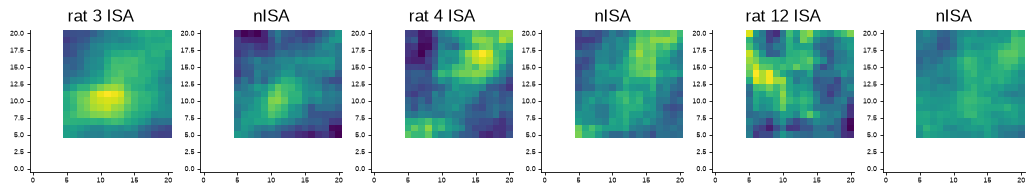

In [10]:
# validate mask per animal
fig, ax = fma.plotting.figure(n=(1,6),size=(26,5))
vmin = 0.000
vmax = 0.005
for j, rat in enumerate([3,4,12]):
    im = []
    for a, isa in enumerate([True,False]):
        reg_data = corr_rip_cat.sel(reg=r,isa=isa,rat=rat)
        reg_data = reg_data.sel(shuffle=False) - reg_data.sel(shuffle=True).mean(dim='shuffle')
        reg_data = mask_quadrant(reg_data.mean(dim='rat',skipna=True).T.values, a=-5, b=-5, c=10, d=10, n=17)
        im.append(fma.plotting.plotColorMap(reg_data, ax=ax[2*j+a])) #,vmin=vmin,vmax=vmax
        print(f'{np.nanmean(reg_data):.6f}',end=' ')
        ax[2*j+a].set(title=f'rat {rat} ISA' if isa else 'nISA')
    fma.plotting.setCLim(im)

/tmp/ipykernel_3903647/3688479792.py:4: RuntimeWarning: Mean of empty slice
  reg_data = np.nanmean(mask_quadrant(reg_data.values, a=-5, b=-5, c=10, d=10, n=17),(2,3)) # upper-right quadrant


[0.69546091]
[0.63987203]


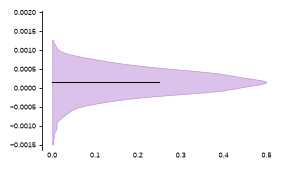

In [68]:
# bootstrap upper-right quadrant
reg_data = corr_rip_cat.sel(reg=r)
reg_data = reg_data.sel(shuffle=False) - reg_data.sel(shuffle=True).mean(dim='shuffle') # increase from shuffle
reg_data = np.nanmean(mask_quadrant(reg_data.values, a=-5, b=-5, c=10, d=10, n=17), (2,3)) # upper-right quadrant

fig, ax = fma.plotting.figure(size=(7,4))
b, _, p, _ = fma.statistics.hierarchicalBootstrap((reg_data[:,0],reg_data[:,1]), (corr_rip_cat.rat,)*2, paired=True)
print(p)

b, _, p, _ = fma.statistics.hierarchicalBootstrap(reg_data[:,0]-reg_data[:,1], corr_rip_cat.rat)
print(p)

fma.plotting.boxPlot(b, mode='violin', color=isau.paperColors('nr'))
fma.plotting.pBar([0,0,p[0]])

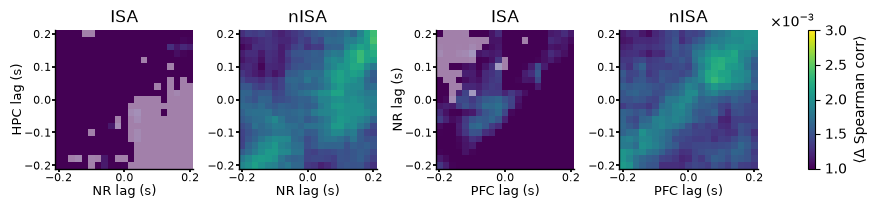

In [28]:
# divide ISA / nISA
fig, ax = fma.plotting.figure(n=(1,4),size=(22,5))
vmin = 0.0010
vmax = 0.003
label = [None,None,None,r'$\langle$﷿﷿ Spearman corr$\rangle$']
for i, r in enumerate(corr_rip_cat.reg.values[[0,2]]):
    for a, isa in enumerate([True,False]):
        reg_data = corr_rip_cat.sel(reg=r,isa=isa)
        reg_data = reg_data.sel(shuffle=False) - reg_data.sel(shuffle=True)
        # significance
        w = sp.stats.wilcoxon(reg_data,axis=0,nan_policy='omit',alternative='greater').pvalue
        _, h = fma.analysis.holmBonferroni(w,return_reject=True)
        # plot result
        cb = plotCMap(reg_data.mean(dim='rat',skipna=True).T,vmin=vmin,vmax=vmax,smooth=.2,alpha=np.where(h,1.0,0.5),bar=label[2*i+a],ax=ax[2*i+a],reg=r)
        ax[2*i+a].set(title='ISA' if isa else 'nISA')
ax[1].set(ylabel=''), ax[3].set(ylabel='')
do_save and fma.plotting.saveFigure(fig,fig_root_supp / 'rippleXCorr2',('png','svg'))

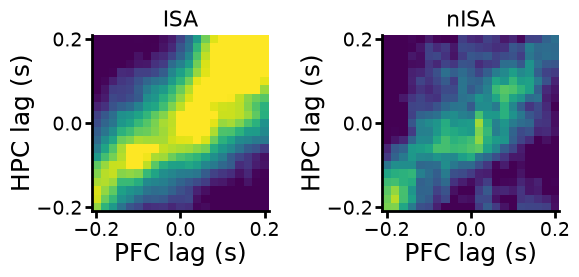

In [6]:
# poster figure
fig, ax = fma.plotting.figure(n=(1,2),size=(5.9,2.7),format='poster')
vmin = 0.0010
vmax = 0.003
label = [None,None,None,None,None,r'$\langle$﷿﷿ Spearman corr$\rangle$']
for i, r in enumerate(corr_rip_cat.reg.values[1:2]):
    for a, isa in enumerate([True,False]):
        reg_data = corr_rip_cat.sel(reg=r,isa=isa)
        reg_data = reg_data.sel(shuffle=False) - reg_data.sel(shuffle=True)
        # significance
        w = sp.stats.wilcoxon(reg_data,axis=0,nan_policy='omit',alternative='greater').pvalue
        _, h = fma.statistics.holmBonferroni(w,return_reject=True)
        # plot result
        out = plotCMap(reg_data.mean(dim='rat',skipna=True).T,vmin=vmin,vmax=vmax,smooth=.2,alpha=np.where(h,1.0,0.5),bar=label[2*i+a],ax=ax[2*i+a],reg=r)
        label[2*i+a] is not None and out[1].ax.ticklabel_format(axis='y', style='sci', scilimits=(-2,-2))
        ax[2*i+a].set_title('ISA' if isa else 'nISA',fontsize=16)

TRY spindles

In [4]:
corr_spin = fma.data.runBatch(batch_file, _laggedSpikeCrossCorr, regs=regs, event='spindles', target=None, shuffle=100, drop_fail=True, parallel=True)
corr_spin_cat = xr.concat(corr_spin, dim='rat', join='outer')
results['spin'] = corr_spin_cat
isau.update_results(results, fres)


Starting Batch, 2026-11-19 01:12:41.678373 

Error in session /mnt/hubel-data-139/karadoc/Rat004_20240303/Rat004_20240303.xml (17)
'float' object is not subscriptable
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.xml (31)
/mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.xml (32)
/mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.xml (33)
/mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.sws not found.
Traceback:
Error in session /mnt/hubel-data-129/blinky/Rat002_20230822/Rat002_20230822.xml (41)
/mnt/hubel-data-129/blinky/Rat002_20230822/Rat002_20230822.sws not found.
Traceback:
Error in session /mnt/hubel-data-129/blinky/Rat002_20230823/Rat002_20230823.xml (42)
/m

In [5]:
corr_spin = fma.data.runBatch(batch_file, _laggedSpikeCrossCorr, when='sleep.*#1', regs=regs, event='spindles', target=None, shuffle=100, drop_fail=True, parallel=True)
corr_spin_cat = xr.concat(corr_spin, dim='rat', join='outer')
results['spin_s2'] = corr_spin_cat
isau.update_results(results, fres)


Starting Batch, 2026-11-19 05:40:53.733021 

Error in session /mnt/hubel-data-139/karadoc/Rat004_20240303/Rat004_20240303.xml (17)
'float' object is not subscriptable
Traceback:
Error in session /mnt/hubel-data-140/karadoc/Rat004_20240313/Rat004_20240313.xml (24)
'float' object is not subscriptable
Traceback:
Error in session /mnt/hubel-data-140/karadoc/Rat004_20240318/Rat004_20240318.xml (29)
'float' object is not subscriptable
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.xml (31)
/mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.xml (32)
/mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.xml (33)
/mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.sws not found.
Tr

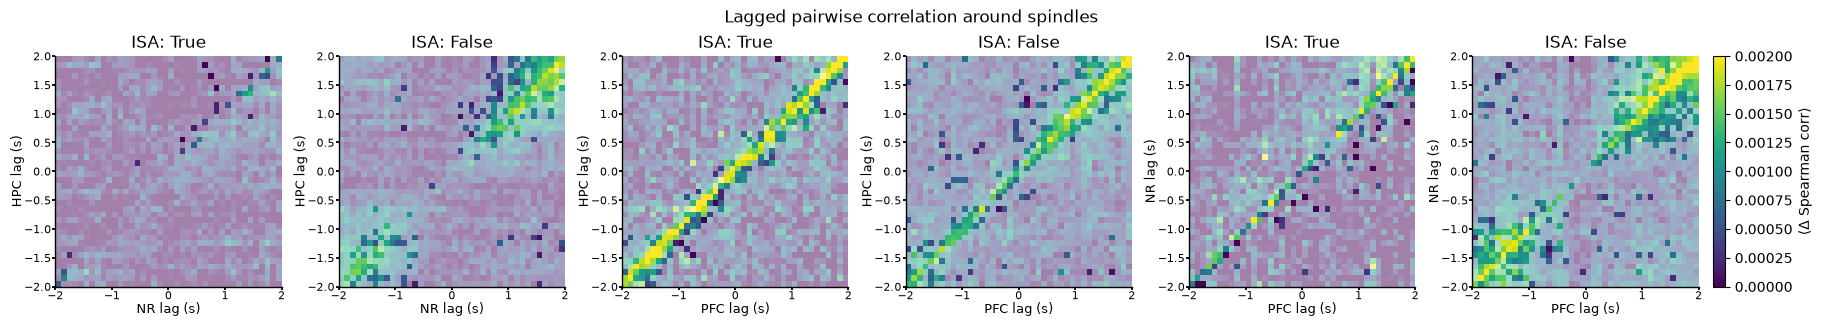

In [135]:
fig, ax = fma.plotting.figure(f'Lagged pairwise correlation around {corr_spin_cat.event.values}',n=(1,6),size=(46,8))
vmin = 0. # 0.026 # for absolute values (not difference)
vmax = 0.002 # 0.032 # for absolute values (not difference)
label = [None,None,None,None,None,r'$\langle$﷿﷿ Spearman corr$\rangle$']
for i, r in enumerate(corr_spin_cat.reg.values[:3]):
    for a, isa in enumerate([True,False]):
        reg_data = corr_spin_cat.sel(reg=r,isa=isa)
        reg_data = reg_data.sel(shuffle=False) - reg_data.sel(shuffle=True)
        # significance
        w = sp.stats.wilcoxon(reg_data,axis=0,nan_policy='omit',alternative='greater').pvalue
        _, h = fma.analysis.holmBonferroni(w,return_reject=True)
        # plot result
        plotCMap(reg_data.mean(dim='rat',skipna=True).T,vmin=vmin,vmax=vmax,smooth=.2,alpha=np.where(h,1.0,0.5),bar=label[2*i+a],ax=ax[2*i+a],reg=r)
        ax[2*i+a].set(title=f'ISA: {isa}')
do_save and fma.plotting.saveFigure(fig,fig_root / 'spindleXCorr2',('png','svg'))

In [7]:
isau.update_results(results, fres)

TEST: figure out which lag is which region

In [111]:
session = fma.data.readBatchFile(batch_file)[0][24]
print(f'session: {session}')
xdata = _laggedSpikeCrossCorr(session,event='ripples',bin=0.1,n_bins=5,step=1,target=[0,2],shift=5,pairs=[[0,1]])

session: /mnt/hubel-data-140/karadoc/Rat004_20240313/Rat004_20240313.xml
lagged (source): nr -0.2
  ref (target): hpc
  ref (target): hpc
lagged (source): nr -0.1
  ref (target): hpc
  ref (target): hpc
lagged (source): nr 0.0
  ref (target): hpc
  ref (target): hpc
lagged (source): nr 0.10000000000000003
  ref (target): hpc
  ref (target): hpc
lagged (source): nr 0.2
  ref (target): hpc
  ref (target): hpc


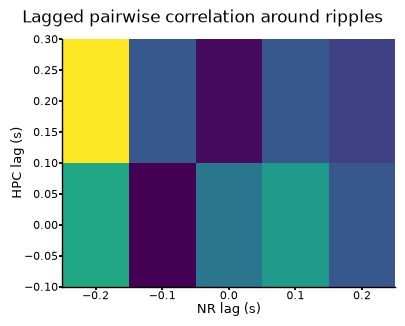

In [118]:
# interpretation: reg1 target, reg2 source
fig, ax = fma.plotting.figure(f'Lagged pairwise correlation around {xdata.event.values}',n=(1,1),size=(10,8))
for i, r in enumerate(xdata.reg.values):
    reg_data = xdata.sel(reg=r,isa=True)
    plotCMap(reg_data.sel(shuffle=False).T,ax=ax[i],reg=r)